# Demo — medroute: Otimização de Rotas para Distribuição de Medicamentos

**Projeto 2 · Tech Challenge Fase 2 · Pós-Graduação FIAP/IADT**

Este notebook demonstra de ponta a ponta o sistema de otimização do
"caixeiro viajante médico" (TSP → VRP) via **Algoritmos Genéticos** e a
integração com **LLM (Gemini)** para instruções, relatórios e Q&A.

> Kernel: use o ambiente Pipenv do projeto (`pipenv run jupyter notebook`,
> ou selecione o interpretador `.virtualenvs\pos-tech-fiap-ia-dev-fase-2-*`).
> As células de LLM degradam graciosamente se a quota da API estiver esgotada.

## 1 · Cenário do problema

Hospital Central (depósito) distribui para 12 pontos — UPAs, clínicas, UBS,
farmácias e pacientes domiciliares — cada um com **demanda** (carga) e
**prioridade clínica**. A frota tem 3 veículos heterogêneos com
**capacidade** e **autonomia** limitadas.

In [1]:
from medroute.data.sample_scenario import build_sample_scenario
from medroute.domain import Priority

depot, deliveries, vehicles = build_sample_scenario()

print(f"Depósito: {depot.name} @ {depot.coord}")
print(f"{'id':>3} {'ponto':<24} {'demanda':>7} {'prioridade':<10}")
for p in deliveries:
    print(f"{p.id:>3} {p.name:<24} {p.demand:>7} {p.priority.name:<10}")
print()
for v in vehicles:
    print(f"Veículo {v.id}: capacidade={v.capacity}, "
          f"autonomia={v.max_distance} km, custo fixo={v.fixed_cost}")

Depósito: Hospital Central (CD) @ (500.0, 200.0)
 id ponto                    demanda prioridade
  0 UPA Norte                      3 CRITICAL  
  1 Clínica Leste                  2 HIGH      
  2 UBS Jardins                    4 REGULAR   
  3 Paciente domiciliar A          1 CRITICAL  
  4 Paciente domiciliar B          2 HIGH      
  5 Hospital Municipal             5 CRITICAL  
  6 UBS Vila Nova                  3 REGULAR   
  7 Clínica Sul                    2 REGULAR   
  8 Farmácia Popular               4 HIGH      
  9 Paciente domiciliar C          1 CRITICAL  
 10 UPA Oeste                      3 REGULAR   
 11 Laboratório Central            2 HIGH      

Veículo 0: capacidade=15.0, autonomia=1200.0 km, custo fixo=50.0
Veículo 1: capacidade=15.0, autonomia=1200.0 km, custo fixo=50.0
Veículo 2: capacidade=18.0, autonomia=1500.0 km, custo fixo=80.0


## 2 · Motor genético (TSP base → VRP)

**Cromossomo** = permutação dos índices de entrega (mesma representação do
TSP base → preserva OX e mutação). Um **decoder guloso** divide a permutação
em rotas por veículo impondo capacidade e autonomia. O **fitness** soma
distância + `prioridade × distância de chegada` + penalidades.

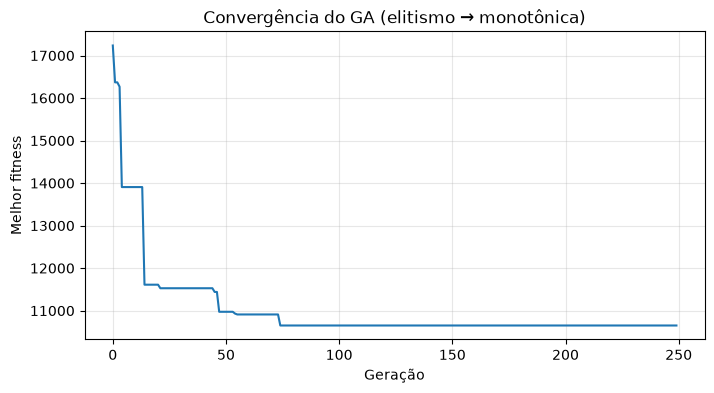

Melhor fitness: 10651.0


In [2]:
import matplotlib.pyplot as plt
from medroute.ga import GAConfig, GeneticVRPSolver

solver = GeneticVRPSolver(
    depot, deliveries, vehicles,
    GAConfig(population_size=120, n_generations=250,
             mutation_probability=0.3, seed=42),
)
result = solver.solve()

plt.figure(figsize=(8, 4))
plt.plot(result.fitness_history)
plt.xlabel('Geração'); plt.ylabel('Melhor fitness')
plt.title('Convergência do GA (elitismo → monotônica)')
plt.grid(alpha=0.3); plt.show()

print(f"Melhor fitness: {result.best_fitness:.1f}")

In [3]:
from medroute.domain import check_autonomy, check_capacity, plan_metrics, route_distance

for route in result.best_plan.routes:
    v = route.vehicle
    print(f"Veículo {v.id}: {route_distance(depot, route):.1f} km | "
          f"carga {route.load}/{v.capacity} | "
          f"capacidade ok: {check_capacity(route)} | "
          f"autonomia ok: {check_autonomy(depot, route)}")
    for i, p in enumerate(route.stops, 1):
        print(f"   {i}. {p.name} [{p.priority.name}]")

print()
print(plan_metrics(depot, result.best_plan))

Veículo 0: 614.4 km | carga 15/15.0 | capacidade ok: True | autonomia ok: True
   1. UPA Norte [CRITICAL]
   2. Paciente domiciliar A [CRITICAL]
   3. Paciente domiciliar B [HIGH]
   4. Clínica Sul [REGULAR]
   5. UPA Oeste [REGULAR]
   6. Laboratório Central [HIGH]
   7. Clínica Leste [HIGH]
Veículo 1: 567.4 km | carga 12/15.0 | capacidade ok: True | autonomia ok: True
   1. Paciente domiciliar C [CRITICAL]
   2. UBS Vila Nova [REGULAR]
   3. Farmácia Popular [HIGH]
   4. UBS Jardins [REGULAR]
Veículo 2: 344.8 km | carga 5/18.0 | capacidade ok: True | autonomia ok: True
   1. Hospital Municipal [CRITICAL]

{'total_distance': 1526.5664329229987, 'vehicles_used': 3, 'deliveries_served': 12, 'deliveries_unserved': 0, 'violations': {'capacity': [], 'autonomy': []}, 'critical_in_second_half': 0}


## 3 · Visualização das rotas

Marcadores coloridos por prioridade (vermelho=CRITICAL, laranja=HIGH,
verde=REGULAR), uma polyline por veículo — camadas ativáveis no canto
superior direito.

In [4]:
from medroute.visualization import MapRenderer

MapRenderer().build_map(depot, result.best_plan)

## 4 · Integração com LLM (Gemini)

O plano do GA é serializado em texto estruturado (`plan_context`) e injetado
em prompts com papel de sistema + formato de saída definido + grounding.
Primeiro, veja exatamente o que a LLM recebe:

In [5]:
from medroute.llm import plan_context

print(plan_context(depot, result.best_plan))

DEPÓSITO: Hospital Central (CD) (todas as rotas partem e retornam aqui)
MÉTRICAS: distância total 1526.6 km | veículos usados 3 | entregas atendidas 12 | não atendidas 0
ROTAS:
  Veículo 0 (capacidade 15, autonomia 1200 km): 614.4 km, carga 15
    1. UPA Norte — prioridade CRITICAL, demanda 3
    2. Paciente domiciliar A — prioridade CRITICAL, demanda 1
    3. Paciente domiciliar B — prioridade HIGH, demanda 2
    4. Clínica Sul — prioridade REGULAR, demanda 2
    5. UPA Oeste — prioridade REGULAR, demanda 3
    6. Laboratório Central — prioridade HIGH, demanda 2
    7. Clínica Leste — prioridade HIGH, demanda 2
  Veículo 1 (capacidade 15, autonomia 1200 km): 567.4 km, carga 12
    1. Paciente domiciliar C — prioridade CRITICAL, demanda 1
    2. UBS Vila Nova — prioridade REGULAR, demanda 3
    3. Farmácia Popular — prioridade HIGH, demanda 4
    4. UBS Jardins — prioridade REGULAR, demanda 4
  Veículo 2 (capacidade 18, autonomia 1500 km): 344.8 km, carga 5
    1. Hospital Municipal — 

In [6]:
from pathlib import Path

try:
    from medroute.llm import RouteReportGenerator, create_default_client
    gen = RouteReportGenerator(create_default_client())
    texto = gen.driver_instructions(depot, result.best_plan)
except Exception as exc:
    # Sem quota/chave: exibe o artefato gerado anteriormente em output/
    print(f"LLM indisponível ({type(exc).__name__}) — "
          f"exibindo instruções geradas anteriormente:\n")
    texto = Path("../output/instrucoes_motoristas.md").read_text(encoding="utf-8")

print(texto[:3000])

C:\Users\mayar\.virtualenvs\pos-tech-fiap-ia-dev-fase-2-XHn_mdBr\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\mayar\pos-tech-fiap-ia-dev-fase-2\src\medroute\llm\client.py:28: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


Abaixo estão as instruções operacionais para os motoristas e a equipe de despacho:

---

## Veículo 0
- **Itinerário:**
  1. Hospital Central (CD) — *Partida*
  2. UPA Norte (Demanda: 3 | CRITICAL)
  3. Paciente domiciliar A (Demanda: 1 | CRITICAL)
  4. Paciente domiciliar B (Demanda: 2 | HIGH)
  5. Clínica Sul (Demanda: 2 | REGULAR)
  6. UPA Oeste (Demanda: 3 | REGULAR)
  7. Laboratório Central (Demanda: 2 | HIGH)
  8. Clínica Leste (Demanda: 2 | HIGH)
  9. Hospital Central (CD) — *Retorno*

- **Alertas para entregas CRITICAL:**
  - **Parada 1 (UPA Norte) e Parada 2 (Paciente domiciliar A):** Itens de suporte à vida e criticidade clínica máxima. Realizar entrega imediata sem desvios de rota. Verificar rigorosamente o lacre da embalagem térmica e os registros do termolábil antes de coletar a assinatura do responsável/paciente.

- **Observações Operacionais:**
  - **Carga vs. Capacidade:** 15 / 15 unidades (**100% de ocupação**). Carregamento no limite máximo; organizar o baú em ordem e

In [7]:
try:
    print("Pergunta: Qual veículo faz mais entregas críticas?\n")
    print(gen.answer_question(depot, result.best_plan,
          "Qual veículo faz mais entregas críticas?"))
except Exception as exc:
    print(f"LLM indisponível ({type(exc).__name__}).")

Pergunta: Qual veículo faz mais entregas críticas?



O **Veículo 0** é o que faz mais entregas críticas, totalizando **2 entregas** com prioridade CRITICAL:

1. **UPA Norte** (demanda: 3)
2. **Paciente domiciliar A** (demanda: 1)

Os veículos 1 e 2 realizam apenas 1 entrega crítica cada.


## 5 · Comparativo de desempenho

GA-VRP vs. baselines: TSP ingênuo (inviável), guloso nearest-neighbor e
amostragem aleatória. Script completo: `scripts/benchmark.py`.

In [8]:
import sys
sys.path.insert(0, "../scripts")
from benchmark import greedy_vrp, naive_tsp, random_search
from medroute.domain.models import Route, Vehicle
from medroute.ga.fitness import evaluate

d_naive = naive_tsp(depot, deliveries)
v0 = vehicles[0]
naive_route = Route(vehicle=v0, stops=deliveries)
print(f"TSP ingênuo: {d_naive:.1f} km — INVIÁVEL "
      f"(carga {naive_route.load} > {v0.capacity}, dist > {v0.max_distance})")

plan_g = greedy_vrp(depot, deliveries, vehicles)
chromo_g = [deliveries.index(p) for r in plan_g.routes for p in r.stops]
fit_g = evaluate(chromo_g, depot, deliveries, vehicles)
print(f"Guloso NN: fitness {fit_g:.1f} (ignora prioridade)")

fit_r = random_search(depot, deliveries, vehicles, n_samples=3000)
print(f"Aleatório (3000): fitness {fit_r:.1f}")

print(f"GA-VRP: fitness {result.best_fitness:.1f}  <- melhor compromisso "
      f"distância × prioridade × restrições")

TSP ingênuo: 2284.2 km — INVIÁVEL (carga 32 > 15.0, dist > 1200.0)
Guloso NN: fitness 11949.8 (ignora prioridade)


Aleatório (3000): fitness 13920.1
GA-VRP: fitness 10651.0  <- melhor compromisso distância × prioridade × restrições


## Conclusão

- **VRP viável** onde o TSP puro falha: frota respeita carga/autonomia e
  prioriza medicamentos críticos.
- **Operadores preservados** do código base (OX, swap, roleta, elitismo);
  a complexidade VRP ficou no decoder + fitness.
- **LLM** transforma o plano em instruções operacionais, relatórios e
  respostas grounded.

Mais detalhes: `docs/architecture.md` · `docs/relatorio_tecnico.md` ·
56 testes em `tests/` (`pipenv run pytest`).